# TOP K CLUSTERS -> MULTIPLE BOXES -> SAM2 
## RELEAF 
## WEEDSGALORE
## EWIS-1 


In [1]:
import os
import sys
import json
import random
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn.functional as F

from torchvision import transforms

from tqdm.auto import tqdm

In [2]:
#Project parhs 
PROJECT_ROOT = Path(
    "/home/zahranadeem/thesis"
)

MODEL_NAME = (
    "facebook/sam2.1-hiera-tiny"
)

# ------------------------------------------------------------
# AgriCLIP
# ------------------------------------------------------------

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

# Same VegAnn-trained aligner used in your original experiment
ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

# ------------------------------------------------------------
# Fine-tuned SAM2
# ------------------------------------------------------------

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

RESULTS_ROOT = (
    PROJECT_ROOT
    / "results"
    / "agriclip_cluster_cross_dataset"
)

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)
print("Results:", RESULTS_ROOT)

Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
Results: /home/zahranadeem/thesis/results/agriclip_cluster_cross_dataset


In [3]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [4]:
#RELEAF PATHS 
RELEAF_ROOT = (
    PROJECT_ROOT
    / "releaf"
)

RELEAF_DATA = (
    RELEAF_ROOT
    / "data"
    / "CWL"
)

RELEAF_TRAIN = RELEAF_DATA / "train"
RELEAF_VALID = RELEAF_DATA / "valid"
RELEAF_TEST = RELEAF_DATA / "test"

RELEAF_IMAGE_DIR = RELEAF_TEST

RELEAF_COCO_JSON = (
    RELEAF_TEST
    / "_annotations.coco.json"
)

print("ReLeaf test:", RELEAF_IMAGE_DIR)
print("COCO:", RELEAF_COCO_JSON)
print("Exists:", RELEAF_COCO_JSON.exists())

ReLeaf test: /home/zahranadeem/thesis/releaf/data/CWL/test
COCO: /home/zahranadeem/thesis/releaf/data/CWL/test/_annotations.coco.json
Exists: True


In [5]:
#ANNOTATIONS 
from pycocotools import mask as coco_mask

In [6]:
with open(
    RELEAF_COCO_JSON,
    "r"
) as f:

    releaf_coco = json.load(f)

print(
    "Images:",
    len(releaf_coco["images"])
)

print(
    "Annotations:",
    len(releaf_coco["annotations"])
)

print("Categories:")

for category in releaf_coco["categories"]:
    print(category)

Images: 345
Annotations: 3021
Categories:
{'id': 1, 'name': 'leaf'}


In [7]:
#organize annotations 
releaf_images_by_id = {
    img["id"]: img
    for img in releaf_coco["images"]
}

releaf_filename_to_id = {
    img["file_name"]: img["id"]
    for img in releaf_coco["images"]
}

releaf_annotations_by_image = {}

for ann in releaf_coco["annotations"]:

    image_id = ann["image_id"]

    if image_id not in releaf_annotations_by_image:
        releaf_annotations_by_image[image_id] = []

    releaf_annotations_by_image[
        image_id
    ].append(ann)

print(
    "Images with annotations:",
    len(releaf_annotations_by_image)
)

Images with annotations: 345


In [8]:
#Releaf mask function 
def releaf_get_mask(
    image_id,
    height,
    width
):

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    annotations = (
        releaf_annotations_by_image.get(
            image_id,
            []
        )
    )

    for ann in annotations:

        segmentation = ann.get(
            "segmentation"
        )

        if segmentation is None:
            continue

        # Polygon
        if isinstance(
            segmentation,
            list
        ):

            rles = coco_mask.frPyObjects(
                segmentation,
                height,
                width
            )

            decoded = coco_mask.merge(
                rles
            )

            decoded = coco_mask.decode(
                decoded
            )

        # RLE
        elif isinstance(
            segmentation,
            dict
        ):

            decoded = coco_mask.decode(
                segmentation
            )

        else:
            continue

        if decoded.ndim == 3:

            decoded = np.any(
                decoded,
                axis=2
            )

        mask[
            decoded > 0
        ] = 1

    return mask

In [9]:
#Building samples 
releaf_samples = []

for img_info in releaf_coco["images"]:

    image_path = (
        RELEAF_IMAGE_DIR
        / img_info["file_name"]
    )

    if image_path.exists():

        releaf_samples.append({
            "image": image_path,
            "image_id": img_info["id"]
        })

print(
    "ReLeaf samples:",
    len(releaf_samples)
)

print(
    releaf_samples[:3]
)

ReLeaf samples: 345
[{'image': PosixPath('/home/zahranadeem/thesis/releaf/data/CWL/test/ave-0041-0002-002.jpg'), 'image_id': 1}, {'image': PosixPath('/home/zahranadeem/thesis/releaf/data/CWL/test/ave-0045-0011-012.jpg'), 'image_id': 2}, {'image': PosixPath('/home/zahranadeem/thesis/releaf/data/CWL/test/ave-0048-0002-026.jpg'), 'image_id': 3}]


In [10]:
#Test one sample 
sample = releaf_samples[0]

image = Image.open(
    sample["image"]
).convert("RGB")

gt_mask = releaf_get_mask(
    sample["image_id"],
    image.height,
    image.width
)

print("Image:", image.size)
print("Mask:", gt_mask.shape)
print("Foreground:", gt_mask.sum())

Image: (231, 184)
Mask: (184, 231)
Foreground: 16188


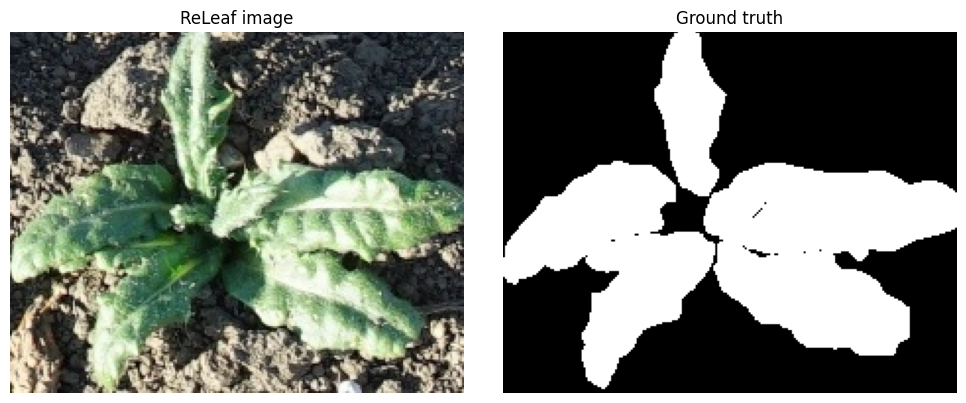

In [11]:
#visualize 
plt.figure(
    figsize=(10, 4)
)

plt.subplot(1, 2, 1)

plt.imshow(image)
plt.title("ReLeaf image")
plt.axis("off")

plt.subplot(1, 2, 2)

plt.imshow(
    gt_mask,
    cmap="gray"
)

plt.title("Ground truth")
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
#WEEDS GALORE PATHS 
WEEDSGALORE_ROOT = (
    PROJECT_ROOT
    / "WeedsGalore_dataset"
)

WEEDSGALORE_GT_DIR = (
    WEEDSGALORE_ROOT
    / "fields"
    / "ground_truth_semantic"
)

print(
    "WeedsGalore:",
    WEEDSGALORE_ROOT
)

print(
    "GT:",
    WEEDSGALORE_GT_DIR
)

print(
    "Exists:",
    WEEDSGALORE_GT_DIR.exists()
)

WeedsGalore: /home/zahranadeem/thesis/WeedsGalore_dataset
GT: /home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic
Exists: True


In [13]:
#BUILD IMAGE MASK PAIRS 
image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".JPG",
    ".JPEG",
    ".PNG"
}

weedsgalore_images = sorted(
    [
        p
        for p in WEEDSGALORE_ROOT.rglob("*")
        if p.is_file()
        and p.suffix in image_extensions
    ]
)

weedsgalore_rgb_images = []

for p in weedsgalore_images:

    try:

        img = Image.open(p)

        if img.mode in [
            "RGB",
            "RGBA"
        ]:

            weedsgalore_rgb_images.append(p)

    except Exception:

        continue

weedsgalore_pairs = []

for image_path in weedsgalore_rgb_images:

    mask_path = (
        WEEDSGALORE_GT_DIR
        / image_path.name
    )

    if mask_path.exists():

        weedsgalore_pairs.append({
            "image": image_path,
            "mask": mask_path
        })

print(
    "WeedsGalore pairs:",
    len(weedsgalore_pairs)
)

WeedsGalore pairs: 156


In [14]:
#Mask function 
test_mask = np.array(
    Image.open(
        weedsgalore_pairs[0]["mask"]
    )
)

print(
    "Mask shape:",
    test_mask.shape
)

print(
    "Unique values:",
    np.unique(test_mask)[:50]
)

Mask shape: (600, 600)
Unique values: [0 1 3 5]


In [15]:
def weedsgalore_get_mask(
    mask_path
):

    mask = np.array(
        Image.open(mask_path)
    )

    # Convert semantic mask to binary foreground
    mask = (
        mask > 0
    ).astype(np.uint8)

    return mask

In [16]:
#Test WeedsGalore 
sample = weedsgalore_pairs[0]

image = Image.open(
    sample["image"]
).convert("RGB")

gt_mask = weedsgalore_get_mask(
    sample["mask"]
)

print(
    "Image:",
    image.size
)

print(
    "Mask:",
    gt_mask.shape
)

print(
    "Foreground:",
    gt_mask.sum()
)

Image: (600, 600)
Mask: (600, 600)
Foreground: 975


In [17]:
#EWIS-1 PATHS 

EWIS1_ROOT = (
    PROJECT_ROOT
    / "EWIS1"
)

EWIS1_DATASET_ROOT = (
    EWIS1_ROOT
    / "EWIS1 Maize, Sorghum & Weed Dataset"
)

EWIS1_IMAGE_DIR = (
    EWIS1_DATASET_ROOT
    / "images"
    / "images"
)

EWIS1_MASK_DIR = (
    EWIS1_DATASET_ROOT
    / "masks"
    / "masks"
)

EWIS1_BBOX_DIR = (
    EWIS1_DATASET_ROOT
    / "bounding_boxes"
    / "bounding_boxes"
)

print(
    "EWIS1 images:",
    EWIS1_IMAGE_DIR
)

print(
    "EWIS1 masks:",
    EWIS1_MASK_DIR
)

print(
    "EWIS1 boxes:",
    EWIS1_BBOX_DIR
)

EWIS1 images: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images
EWIS1 masks: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks
EWIS1 boxes: /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/bounding_boxes/bounding_boxes


In [18]:
#bulding mask and image pairs 
ewis1_images = sorted(
    [
        p
        for p in EWIS1_IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower()
        in {
            ".png",
            ".jpg",
            ".jpeg"
        }
    ]
)

ewis1_masks = sorted(
    [
        p
        for p in EWIS1_MASK_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".png"
    ]
)

mask_lookup = {
    p.stem: p
    for p in ewis1_masks
}

ewis1_pairs = []

for image_path in ewis1_images:

    mask_path = mask_lookup.get(
        image_path.stem
    )

    if mask_path is not None:

        ewis1_pairs.append({
            "image": image_path,
            "mask": mask_path
        })

print(
    "EWIS1 images:",
    len(ewis1_images)
)

print(
    "EWIS1 masks:",
    len(ewis1_masks)
)

print(
    "EWIS1 matched pairs:",
    len(ewis1_pairs)
)


EWIS1 images: 88
EWIS1 masks: 88
EWIS1 matched pairs: 88


In [19]:
#Inspecting maks 
test_mask = np.array(
    Image.open(
        ewis1_pairs[0]["mask"]
    )
)

print(
    "Shape:",
    test_mask.shape
)

print(
    "Unique values:",
    np.unique(test_mask)[:50]
)


Shape: (3640, 5464, 3)
Unique values: [  0  14  31 119 127 180 255]


In [20]:
def ewis1_get_mask(
    mask_path
):

    mask = np.array(
        Image.open(mask_path)
    )

    mask = (
        mask > 0
    ).astype(np.uint8)

    return mask

In [21]:
#Test EWIS1 
sample = ewis1_pairs[0]

image = Image.open(
    sample["image"]
).convert("RGB")

gt_mask = ewis1_get_mask(
    sample["mask"]
)

print(
    "Image:",
    image.size
)

print(
    "Mask:",
    gt_mask.shape
)

print(
    "Foreground:",
    gt_mask.sum()
)

Image: (5464, 3640)
Mask: (3640, 5464, 3)
Foreground: 599214


# CLUSTER PIPELINE NOW 

In [22]:
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

In [23]:
#LOAD DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_model = dino_model.to(device)

dino_model.eval()

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO loaded.


In [24]:
#Import ASGRICLIP 
if str(ALIGNMENT_DIR) not in sys.path:

    sys.path.insert(
        0,
        str(ALIGNMENT_DIR)
    )

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print(
    "AgriCLIP modules imported."
)


AgriCLIP modules imported.


In [25]:
#Loading Vegann trained Agriclip 
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50"
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = (
    text_to_concept.linear_aligner
)

print(
    "VegAnn-trained AgriCLIP aligner loaded."
)

print(
    "W:",
    tuple(aligner.W.shape)
)

print(
    "b:",
    tuple(aligner.b.shape)
)

VegAnn-trained AgriCLIP aligner loaded.
W: (512, 2048)
b: (512,)


In [26]:
#DINO LAYER 4 HOOK 
captured_feature_map = None


def capture_layer4_output(
    module,
    inputs,
    output
):

    global captured_feature_map

    captured_feature_map = (
        output.detach()
    )


hook_handle = (
    dino_model.layer4.register_forward_hook(
        capture_layer4_output
    )
)

print(
    "Layer4 hook registered."
)

Layer4 hook registered.


In [27]:
#ExtractDINO features 
@torch.no_grad()
def extract_dino_patch_features(
    pil_image
):

    global captured_feature_map

    captured_feature_map = None

    image_tensor = (
        dino_transform(
            pil_image
        )
        .unsqueeze(0)
        .to(device)
    )

    _ = dino_model(
        image_tensor
    )

    if captured_feature_map is None:

        raise RuntimeError(
            "Layer4 hook captured nothing."
        )

    if captured_feature_map.ndim != 4:

        raise RuntimeError(
            "Expected B,C,H,W feature map."
        )

    _, channels, grid_h, grid_w = (
        captured_feature_map.shape
    )

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(
            grid_h * grid_w,
            channels
        )
        .contiguous()
    )

    return (
        patch_features,
        grid_h,
        grid_w
    )

In [28]:
#Align DINO features into AgriCLIP space 
@torch.no_grad()
def align_patch_features(
    patch_features
):

    patch_features = (
        patch_features
        .float()
        .to(device)
    )

    aligned_features = (
        aligner.get_aligned_representation(
            patch_features
        )
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1
    )

    return aligned_features

In [29]:
VEGETATION_PROMPTS = [

    "A crop field populated by healthy plants, captured from a nadir view using a handheld camera.",

    "An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.",

    "A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.",

    "An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.",

    "Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.",

    "Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera."
]

print(
    "Number of prompts:",
    len(VEGETATION_PROMPTS)
)

Number of prompts: 6


In [30]:
#Encode prompts 
@torch.no_grad()
def encode_prompt_set(
    prompts
):

    embeddings = []

    for prompt in prompts:

        embedding = (
            text_to_concept.encode_text(
                [[prompt]]
            )
        )

        if isinstance(
            embedding,
            np.ndarray
        ):

            embedding = torch.from_numpy(
                embedding
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings
    )

    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    mean_embedding = (
        embeddings.mean(dim=0)
    )

    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return (
        embeddings,
        mean_embedding
    )


vegetation_text_embeddings, vegetation_embedding = (
    encode_prompt_set(
        VEGETATION_PROMPTS
    )
)

print(
    vegetation_text_embeddings.shape
)

print(
    vegetation_embedding.shape
)

torch.Size([6, 512])
torch.Size([512])


In [31]:
#Load fine tuned SAM2 
from transformers import (
    Sam2Model,
    Sam2Processor
)

sam2_processor = (
    Sam2Processor.from_pretrained(
        MODEL_NAME
    )
)

sam2_model = (
    Sam2Model.from_pretrained(
        MODEL_NAME
    )
)

checkpoint = torch.load(
    SAM2_CHECKPOINT,
    map_location="cpu"
)

if (
    isinstance(checkpoint, dict)
    and
    "mask_decoder_state_dict"
    in checkpoint
):

    decoder_state = (
        checkpoint[
            "mask_decoder_state_dict"
        ]
    )

elif isinstance(
    checkpoint,
    dict
):

    decoder_state = checkpoint

else:

    raise TypeError(
        "Unsupported checkpoint."
    )

load_result = (
    sam2_model.mask_decoder.load_state_dict(
        decoder_state,
        strict=True
    )
)

sam2_model = (
    sam2_model
    .to(device)
)

sam2_model.eval()

print(
    "Fine-tuned SAM2 loaded."
)

print(load_result)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Fine-tuned SAM2 loaded.
<All keys matched successfully>


In [32]:
from scipy.ndimage import label

In [33]:
@torch.no_grad()
def generate_agriclip_cluster_boxes(
    image,
    top_k=8,
    margin=25,
    min_cluster_size=1,
    connectivity=8
):

    # --------------------------------------------------------
    # 1. DINO spatial features
    # --------------------------------------------------------

    patch_features, grid_h, grid_w = (
        extract_dino_patch_features(
            image
        )
    )

    # --------------------------------------------------------
    # 2. Project into AgriCLIP concept space
    # --------------------------------------------------------

    aligned_features = (
        align_patch_features(
            patch_features
        )
    )

    # --------------------------------------------------------
    # 3. Patch-text similarity
    # --------------------------------------------------------

    patch_scores = (
        aligned_features
        @ vegetation_embedding
    )

    scores = (
        patch_scores
        .detach()
        .cpu()
        .numpy()
    )

    # --------------------------------------------------------
    # 4. Select top-K patches
    # --------------------------------------------------------

    top_k = min(
        top_k,
        len(scores)
    )

    topk_indices = (
        np.argsort(scores)[::-1][:top_k]
    )

    # --------------------------------------------------------
    # 5. Create binary top-K grid
    # --------------------------------------------------------

    selected_grid = np.zeros(
        (grid_h, grid_w),
        dtype=np.uint8
    )

    for idx in topk_indices:

        r = idx // grid_w
        c = idx % grid_w

        selected_grid[r, c] = 1

    # --------------------------------------------------------
    # 6. Find spatial clusters
    # --------------------------------------------------------
    # 8-connectivity:
    #
    # X X X
    # X X X
    # X X X
    #
    # Diagonal neighboring patches are also connected.

    if connectivity == 8:

        structure = np.ones(
            (3, 3),
            dtype=np.uint8
        )

    elif connectivity == 4:

        structure = np.array([
            [0, 1, 0],
            [1, 1, 1],
            [0, 1, 0]
        ], dtype=np.uint8)

    else:

        raise ValueError(
            "connectivity must be either 4 or 8"
        )

    labeled_grid, num_clusters = label(
        selected_grid,
        structure=structure
    )

    # --------------------------------------------------------
    # 7. Convert each cluster into a box
    # --------------------------------------------------------

    H = image.height
    W = image.width

    patch_h = H / grid_h
    patch_w = W / grid_w

    cluster_boxes = []
    cluster_scores = []
    cluster_sizes = []

    for cluster_id in range(
        1,
        num_clusters + 1
    ):

        rows, cols = np.where(
            labeled_grid == cluster_id
        )

        # ----------------------------------------------------
        # Filter very small clusters
        # ----------------------------------------------------

        if len(rows) < min_cluster_size:
            continue

        # ----------------------------------------------------
        # Convert patch coordinates to image coordinates
        # ----------------------------------------------------

        x1 = int(
            cols.min() * patch_w
        )

        y1 = int(
            rows.min() * patch_h
        )

        x2 = int(
            (cols.max() + 1) * patch_w
        )

        y2 = int(
            (rows.max() + 1) * patch_h
        )

        # ----------------------------------------------------
        # Add margin around the box
        # ----------------------------------------------------

        x1 = max(
            0,
            x1 - margin
        )

        y1 = max(
            0,
            y1 - margin
        )

        x2 = min(
            W - 1,
            x2 + margin
        )

        y2 = min(
            H - 1,
            y2 + margin
        )

        # ----------------------------------------------------
        # Get patch indices belonging to this cluster
        # ----------------------------------------------------

        cluster_patch_indices = []

        for r, c in zip(
            rows,
            cols
        ):

            cluster_patch_indices.append(
                r * grid_w + c
            )

        cluster_patch_indices = np.array(
            cluster_patch_indices
        )

        # ----------------------------------------------------
        # Calculate mean AgriCLIP score for the cluster
        # ----------------------------------------------------

        mean_score = float(
            scores[
                cluster_patch_indices
            ].mean()
        )

        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        cluster_boxes.append([
            x1,
            y1,
            x2,
            y2
        ])

        cluster_scores.append(
            mean_score
        )

        cluster_sizes.append(
            len(rows)
        )

    # --------------------------------------------------------
    # 8. Return results
    # --------------------------------------------------------

    return {
        "boxes": np.array(
            cluster_boxes,
            dtype=np.int32
        ),

        "cluster_scores": np.array(
            cluster_scores
        ),

        "cluster_sizes": np.array(
            cluster_sizes
        ),

        "num_clusters": len(
            cluster_boxes
        ),

        "scores": scores,

        "topk_indices": topk_indices,

        "grid_h": grid_h,

        "grid_w": grid_w,

        "selected_grid": selected_grid,

        "labeled_grid": labeled_grid
    }

In [34]:
#Test cluster generation 
sample = releaf_samples[0]

image = Image.open(
    sample["image"]
).convert("RGB")

cluster_result = (
    generate_agriclip_cluster_boxes(
        image,
        top_k=8
    )
)

print(
    "Number of clusters:",
    cluster_result["num_clusters"]
)

print(
    "Boxes:"
)

print(
    cluster_result["boxes"]
)

print(
    "Cluster sizes:",
    cluster_result["cluster_sizes"]
)

print(
    "Cluster scores:",
    cluster_result["cluster_scores"]
)

Number of clusters: 4
Boxes:
[[  0   0  91  51]
 [140   0 230  51]
 [  8  80  91 183]
 [ 74 106 157 182]]
Cluster sizes: [2 2 3 1]
Cluster scores: [0.65176582 0.64986151 0.68840432 0.65295857]


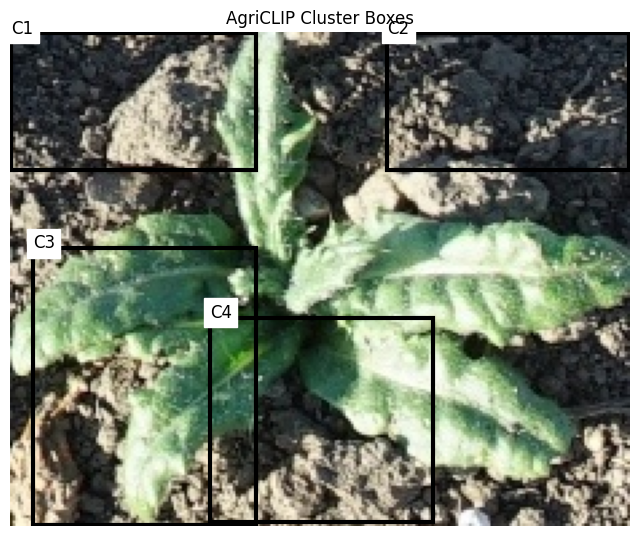

In [35]:
#Visualize cluster boxes '
import matplotlib.patches as patches

fig, ax = plt.subplots(
    figsize=(8, 8)
)

ax.imshow(image)

boxes = cluster_result["boxes"]

for i, box in enumerate(boxes):

    x1, y1, x2, y2 = box

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=3
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1,
        f"C{i+1}",
        fontsize=12,
        backgroundcolor="white"
    )

ax.set_title(
    "AgriCLIP Cluster Boxes"
)

ax.axis("off")

plt.show()

In [36]:
#SAM2 PREDICTION 
@torch.no_grad()
def sam2_predict_cluster_boxes(
    image,
    boxes
):

    if len(boxes) == 0:

        return (
            np.zeros(
                (image.height, image.width),
                dtype=np.uint8
            ),
            0.0
        )

    input_boxes = [
        [
            box.tolist()
            for box in boxes
        ]
    ]

    inputs = sam2_processor(
        images=image,
        input_boxes=input_boxes,
        return_tensors="pt"
    )

    inputs = {
        k: (
            v.to(device)
            if torch.is_tensor(v)
            else v
        )
        for k, v in inputs.items()
    }

    outputs = sam2_model(
        **inputs
    )

    # --------------------------------------------------------
    # Decode masks for every input box
    # --------------------------------------------------------

    all_masks = []

    all_confidences = []

    num_boxes = len(boxes)

    for box_idx in range(
        num_boxes
    ):

        best_idx = (
            outputs
            .iou_scores[
                0,
                box_idx
            ]
            .argmax()
            .item()
        )

        logits = (
            outputs.pred_masks[
                0,
                box_idx,
                best_idx
            ]
        )

        probability = torch.sigmoid(
            logits
        )

        original_height = int(
            inputs[
                "original_sizes"
            ][0, 0].item()
        )

        original_width = int(
            inputs[
                "original_sizes"
            ][0, 1].item()
        )

        probability = F.interpolate(
            probability[
                None,
                None
            ],
            size=(
                original_height,
                original_width
            ),
            mode="bilinear",
            align_corners=False
        )[0, 0]

        mask = (
            probability >= 0.5
        ).cpu().numpy().astype(
            np.uint8
        )

        confidence = (
            outputs
            .iou_scores[
                0,
                box_idx,
                best_idx
            ]
            .item()
        )

        all_masks.append(mask)

        all_confidences.append(
            confidence
        )

    # --------------------------------------------------------
    # Merge predicted cluster masks
    # --------------------------------------------------------

    final_mask = np.any(
        np.stack(all_masks),
        axis=0
    ).astype(np.uint8)

    mean_confidence = float(
        np.mean(
            all_confidences
        )
    )

    return (
        final_mask,
        mean_confidence
    )

In [37]:
#METRICS 
def compute_binary_metrics(
    prediction,
    ground_truth
):

    prediction = np.asarray(
        prediction
    )

    ground_truth = np.asarray(
        ground_truth
    )

    # --------------------------------------------------
    # Convert multi-channel GT to 2D
    # --------------------------------------------------

    if ground_truth.ndim == 3:

        ground_truth = np.any(
            ground_truth > 0,
            axis=2
        )

    if prediction.ndim == 3:

        prediction = np.any(
            prediction > 0,
            axis=2
        )

    # --------------------------------------------------
    # Convert to boolean
    # --------------------------------------------------

    prediction = prediction.astype(bool)
    ground_truth = ground_truth.astype(bool)

    # --------------------------------------------------
    # Check dimensions
    # --------------------------------------------------

    if prediction.shape != ground_truth.shape:

        raise ValueError(
            f"Prediction and GT shapes do not match: "
            f"{prediction.shape} vs {ground_truth.shape}"
        )

    # --------------------------------------------------
    # Metrics
    # --------------------------------------------------

    intersection = np.logical_and(
        prediction,
        ground_truth
    ).sum()

    union = np.logical_or(
        prediction,
        ground_truth
    ).sum()

    pred_pixels = prediction.sum()
    gt_pixels = ground_truth.sum()

    iou = (
        intersection / union
        if union > 0
        else 1.0
    )

    dice_denominator = (
        pred_pixels + gt_pixels
    )

    dice = (
        2.0 * intersection / dice_denominator
        if dice_denominator > 0
        else 1.0
    )

    precision = (
        intersection / pred_pixels
        if pred_pixels > 0
        else 0.0
    )

    recall = (
        intersection / gt_pixels
        if gt_pixels > 0
        else 0.0
    )

    return {
        "iou": float(iou),
        "dice": float(dice),
        "precision": float(precision),
        "recall": float(recall),
        "intersection": int(intersection),
        "union": int(union),
        "pred_pixels": int(pred_pixels),
        "gt_pixels": int(gt_pixels),
    }

In [45]:
def compute_box_iou(boxes, gt_mask, H, W):
    """
    Compute IoU between merged cluster boxes and
    the ground-truth bounding box.
    """

    # --------------------------------------------------
    # If the cluster generator returned a dictionary,
    # extract the actual boxes
    # --------------------------------------------------

    if isinstance(boxes, dict):

        if "boxes" not in boxes:
            raise ValueError(
                "Dictionary does not contain a 'boxes' key."
            )

        boxes = boxes["boxes"]

    # --------------------------------------------------
    # Convert to numpy
    # --------------------------------------------------

    boxes = np.asarray(boxes)

    # No boxes
    if boxes.size == 0:
        return 0.0, np.zeros(
            (H, W),
            dtype=np.uint8
        )

    # Single box: [x1,y1,x2,y2]
    if boxes.ndim == 1:

        if boxes.shape[0] != 4:
            raise ValueError(
                f"Expected one box with 4 values, "
                f"got shape {boxes.shape}"
            )

        boxes = boxes.reshape(1, 4)

    # Multiple boxes
    elif boxes.ndim == 2:

        if boxes.shape[1] != 4:
            raise ValueError(
                f"Expected boxes with shape (N,4), "
                f"got {boxes.shape}"
            )

    else:
        raise ValueError(
            f"Unexpected boxes shape: {boxes.shape}"
        )

    # --------------------------------------------------
    # GT mask → GT bounding box
    # --------------------------------------------------

    gt_mask = np.asarray(gt_mask)

    if gt_mask.ndim == 3:
        gt_mask = gt_mask[..., 0]

    gt_mask = (
        gt_mask > 0
    ).astype(np.uint8)

    ys, xs = np.where(
        gt_mask > 0
    )

    if len(xs) == 0:
        return 0.0, np.zeros(
            (H, W),
            dtype=np.uint8
        )

    gt_x1 = xs.min()
    gt_y1 = ys.min()
    gt_x2 = xs.max()
    gt_y2 = ys.max()

    # --------------------------------------------------
    # Merge all cluster boxes
    # --------------------------------------------------

    box_mask = np.zeros(
        (H, W),
        dtype=np.uint8
    )

    for box in boxes:

        x1, y1, x2, y2 = (
            box.astype(int)
        )

        x1 = max(
            0,
            min(x1, W - 1)
        )

        x2 = max(
            0,
            min(x2, W - 1)
        )

        y1 = max(
            0,
            min(y1, H - 1)
        )

        y2 = max(
            0,
            min(y2, H - 1)
        )

        if x2 >= x1 and y2 >= y1:

            box_mask[
                y1:y2 + 1,
                x1:x2 + 1
            ] = 1

    # --------------------------------------------------
    # GT bounding-box mask
    # --------------------------------------------------

    gt_box_mask = np.zeros(
        (H, W),
        dtype=np.uint8
    )

    gt_box_mask[
        gt_y1:gt_y2 + 1,
        gt_x1:gt_x2 + 1
    ] = 1

    # --------------------------------------------------
    # IoU
    # --------------------------------------------------

    intersection = np.logical_and(
        box_mask,
        gt_box_mask
    ).sum()

    union = np.logical_or(
        box_mask,
        gt_box_mask
    ).sum()

    if union == 0:
        iou = 0.0
    else:
        iou = (
            intersection / union
        )

    return float(iou), box_mask

In [66]:
def evaluate_dataset(
    dataset_name,
    samples,
    get_image_fn,
    get_mask_fn,
    top_k=8,
    margin=25,
    max_samples=None
):

    print(
        "\n" + "=" * 60
    )
    print(
        f"{dataset_name} Evaluation"
    )
    print(
        "=" * 60
    )

    # --------------------------------------------------
    # Select samples
    # --------------------------------------------------

    if max_samples is not None:
        eval_samples = samples[:max_samples]
    else:
        eval_samples = samples

    results = []

    # --------------------------------------------------
    # Evaluation loop
    # --------------------------------------------------

    for idx, sample in enumerate(
        tqdm(eval_samples)
    ):

        try:

            # ------------------------------------------
            # Load image
            # ------------------------------------------

            image = get_image_fn(
                sample
            )

            # ------------------------------------------
            # Load GT mask
            # ------------------------------------------

            gt_mask = get_mask_fn(
                sample,
                image
            )

            gt_mask = np.asarray(
                gt_mask
            )

            # Convert RGB/RGBA GT to 2D
            if gt_mask.ndim == 3:

                gt_mask = np.any(
                    gt_mask > 0,
                    axis=2
                )

            gt_mask = (
                gt_mask > 0
            ).astype(np.uint8)

            H, W = gt_mask.shape

            # ------------------------------------------
            # Generate AgriCLIP cluster boxes
            # ------------------------------------------

            cluster_output = (
                generate_agriclip_cluster_boxes(
                    image,
                    top_k=top_k,
                    margin=margin
                )
            )

            # ------------------------------------------
            # Extract boxes
            # ------------------------------------------

            if isinstance(
                cluster_output,
                dict
            ):

                boxes = cluster_output[
                    "boxes"
                ]

                num_clusters = (
                    cluster_output.get(
                        "num_clusters",
                        len(boxes)
                    )
                )

            else:

                boxes = cluster_output

                num_clusters = len(
                    boxes
                )

            # ------------------------------------------
            # Cluster Box IoU
            # ------------------------------------------

            box_iou, box_mask = (
                compute_box_iou(
                    boxes,
                    gt_mask,
                    H,
                    W
                )
            )

            # ------------------------------------------
            # SAM2 prediction
            # ------------------------------------------

            start_time = time.time()

            pred_mask, confidence = (
                sam2_predict_cluster_boxes(
                    image,
                    boxes
                )
            )

            runtime = (
                time.time()
                - start_time
            )

            # ------------------------------------------
            # Segmentation metrics
            # ------------------------------------------

            metrics = compute_binary_metrics(
                pred_mask,
                gt_mask
            )

            # ------------------------------------------
            # Store results
            # ------------------------------------------

            results.append({

                "image_id": idx,

                "num_clusters":
                    num_clusters,

                "cluster_box_iou":
                    box_iou,

                "iou":
                    metrics["iou"],

                "dice":
                    metrics["dice"],

                "precision":
                    metrics["precision"],

                "recall":
                    metrics["recall"],

                "sam2_confidence":
                    float(confidence),

                "runtime":
                    runtime
            })

        except Exception as e:

            print(
                f"Failed image {idx}: {e}"
            )

    # --------------------------------------------------
    # Convert to DataFrame
    # --------------------------------------------------

    results_df = pd.DataFrame(
        results
    )

    # --------------------------------------------------
    # Summary
    # --------------------------------------------------

    print(
        "\n" + "=" * 60
    )
    print(
        f"{dataset_name} Results"
    )
    print(
        "=" * 60
    )

    print(
        "Images:",
        len(results_df)
    )

    if len(results_df) > 0:

        print(
            "Mean clusters:",
            f"{results_df['num_clusters'].mean():.2f}"
        )

        print(
            "Mean Cluster Box IoU:",
            f"{results_df['cluster_box_iou'].mean() * 100:.2f}%"
        )

        print(
            "Mean SAM2 IoU:",
            f"{results_df['iou'].mean() * 100:.2f}%"
        )

        print(
            "Mean Dice:",
            f"{results_df['dice'].mean() * 100:.2f}%"
        )

        print(
            "Mean Precision:",
            f"{results_df['precision'].mean() * 100:.2f}%"
        )

        print(
            "Mean Recall:",
            f"{results_df['recall'].mean() * 100:.2f}%"
        )

        print(
            "Mean SAM2 confidence:",
            f"{results_df['sam2_confidence'].mean() * 100:.2f}%"
        )

        print(
            "Mean runtime:",
            f"{results_df['runtime'].mean():.4f} sec"
        )

    return results_df

In [47]:
#REELAF ADAPTER
def releaf_get_image(
    sample
):

    return Image.open(
        sample["image"]
    ).convert("RGB")


def releaf_get_mask_for_eval(
    sample,
    image
):

    return releaf_get_mask(
        sample["image_id"],
        image.height,
        image.width
    )

In [50]:
#RUN RELEAF 
releaf_test_results = evaluate_dataset(
    dataset_name="ReLeaf",
    samples=releaf_samples,
    get_image_fn=releaf_get_image,
    get_mask_fn=releaf_get_mask_for_eval,
    top_k=8,
    margin=25,
    max_samples=20
)


ReLeaf Evaluation


  0%|          | 0/20 [00:00<?, ?it/s]


ReLeaf Results
Images: 20
Mean clusters: 3.55
Mean Cluster Box IoU: 54.99%
Mean SAM2 IoU: 78.39%
Mean Dice: 87.31%
Mean Precision: 79.36%
Mean Recall: 98.54%
Mean SAM2 confidence: 94.68%
Mean runtime: 0.0297 sec


In [58]:
releaf_results = evaluate_dataset(
    dataset_name="ReLeaf",
    samples=releaf_samples,
    get_image_fn=releaf_get_image,
    get_mask_fn=releaf_get_mask_for_eval,
    top_k=8,
    margin=5,
    max_samples=None
)


ReLeaf Evaluation


  0%|          | 0/345 [00:00<?, ?it/s]


ReLeaf Results
Images: 345
Mean clusters: 3.60
Mean Cluster Box IoU: 27.40%
Mean SAM2 IoU: 80.07%
Mean Dice: 88.29%
Mean Precision: 82.90%
Mean Recall: 95.80%
Mean SAM2 confidence: 94.54%
Mean runtime: 0.0248 sec


In [52]:
#WEEDAGALORE ADPATER 
def weedsgalore_get_image(
    sample
):

    return Image.open(
        sample["image"]
    ).convert("RGB")


def weedsgalore_get_mask_for_eval(
    sample,
    image
):

    return weedsgalore_get_mask(
        sample["mask"]
    )

In [53]:
#TEST WEEDSGALORE 
weedsgalore_test_results = evaluate_dataset(
    dataset_name="WeedsGalore",
    samples=weedsgalore_pairs,
    get_image_fn=weedsgalore_get_image,
    get_mask_fn=weedsgalore_get_mask_for_eval,
    top_k=8,
    margin=25,
    max_samples=20
)


WeedsGalore Evaluation


  0%|          | 0/20 [00:00<?, ?it/s]


WeedsGalore Results
Images: 20
Mean clusters: 3.40
Mean Cluster Box IoU: 33.18%
Mean SAM2 IoU: 40.82%
Mean Dice: 56.95%
Mean Precision: 67.80%
Mean Recall: 50.76%
Mean SAM2 confidence: 74.02%
Mean runtime: 0.0263 sec


In [54]:
weedsgalore_results = evaluate_dataset(
    dataset_name="WeedsGalore",
    samples=weedsgalore_pairs,
    get_image_fn=weedsgalore_get_image,
    get_mask_fn=weedsgalore_get_mask_for_eval,
    top_k=8,
    margin=25,
    max_samples=None
)


WeedsGalore Evaluation


  0%|          | 0/156 [00:00<?, ?it/s]


WeedsGalore Results
Images: 156
Mean clusters: 3.25
Mean Cluster Box IoU: 34.81%
Mean SAM2 IoU: 45.07%
Mean Dice: 60.90%
Mean Precision: 75.40%
Mean Recall: 52.66%
Mean SAM2 confidence: 81.45%
Mean runtime: 0.0260 sec


In [55]:
#EWSI1 ADAPTER 
def ewis1_get_image(
    sample
):

    return Image.open(
        sample["image"]
    ).convert("RGB")


def ewis1_get_mask_for_eval(
    sample,
    image=None
):
    

    mask_path = sample["mask"]

    mask = np.array(
        Image.open(mask_path)
    )

    print(
        "Original EWIS1 mask shape:",
        mask.shape
    )

    # --------------------------------------------------
    # Convert RGB/RGBA mask to 2D
    # --------------------------------------------------

    if mask.ndim == 3:

        mask = np.any(
            mask > 0,
            axis=2
        )

    else:

        mask = mask > 0

    # --------------------------------------------------
    # Convert to uint8 binary mask
    # --------------------------------------------------

    mask = mask.astype(
        np.uint8
    )

    # --------------------------------------------------
    # Safety check against image dimensions
    # --------------------------------------------------

    if image is not None:

        expected_shape = (
            image.height,
            image.width
        )

        if mask.shape != expected_shape:

            print(
                "WARNING: Mask/image size mismatch"
            )

            print(
                "Mask:",
                mask.shape
            )

            print(
                "Image:",
                expected_shape
            )

    return mask

In [56]:
#TEST EWIS1 
ewis1_test_results = evaluate_dataset(
    dataset_name="EWIS1",
    samples=ewis1_pairs,
    get_image_fn=ewis1_get_image,
    get_mask_fn=ewis1_get_mask_for_eval,
    top_k=8,
    margin=25,
    max_samples=20
)


EWIS1 Evaluation


  0%|          | 0/20 [00:00<?, ?it/s]

Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)

EWIS1 Results
Images: 20
Mean clusters: 3.20
Mean Cluster Box IoU: 24.02%
Mean SAM2 IoU: 38.24%
Mean Dice: 54.79%
Mean Precision: 66.62%
Me

In [57]:
ewis1_results = evaluate_dataset(
    dataset_name="EWIS1",
    samples=ewis1_pairs,
    get_image_fn=ewis1_get_image,
    get_mask_fn=ewis1_get_mask_for_eval,
    top_k=8,
    margin=25,
    max_samples=None
)


EWIS1 Evaluation


  0%|          | 0/88 [00:00<?, ?it/s]

Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EWIS1 mask shape: (3640, 5464, 3)
Original EW

In [59]:
def summarize_results(
    name,
    df
):

    print("\n" + "=" * 60)

    print(name)

    print("=" * 60)

    print(
        "Images:",
        len(df)
    )

    print(
        f"Mean clusters: "
        f"{df['num_clusters'].mean():.2f}"
    )

    print(
        f"Mean IoU: "
        f"{df['iou'].mean()*100:.2f}%"
    )

    print(
        f"Mean Dice: "
        f"{df['dice'].mean()*100:.2f}%"
    )

    print(
        f"Mean Precision: "
        f"{df['precision'].mean()*100:.2f}%"
    )

    print(
        f"Mean Recall: "
        f"{df['recall'].mean()*100:.2f}%"
    )

    print(
        f"Mean SAM2 confidence: "
        f"{df['sam2_confidence'].mean()*100:.2f}%"
    )

    print(
        f"Mean runtime: "
        f"{df['runtime_sec'].mean():.4f} sec"
    )

In [60]:
summarize_results(
    "ReLeaf",
    releaf_results
)

summarize_results(
    "WeedsGalore",
    weedsgalore_results
)

summarize_results(
    "EWIS1",
    ewis1_results
)


ReLeaf
Images: 345
Mean clusters: 3.60
Mean IoU: 80.07%
Mean Dice: 88.29%
Mean Precision: 82.90%
Mean Recall: 95.80%
Mean SAM2 confidence: 94.54%


KeyError: 'runtime_sec'

In [ ]:
cross_dataset = pd.DataFrame({

    "Dataset": [
        "VegAnn",
        "ReLeaf",
        "WeedsGalore",
        "EWIS1"
    ],

    "IoU": [
        70.62,   # replace if this is your final cluster-box VegAnn result
        releaf_results["iou"].mean() * 100,
        weedsgalore_results["iou"].mean() * 100,
        ewis1_results["iou"].mean() * 100
    ],

    "Dice": [
        80.30,
        releaf_results["dice"].mean() * 100,
        weedsgalore_results["dice"].mean() * 100,
        ewis1_results["dice"].mean() * 100
    ],

    "Precision": [
        90.84,
        releaf_results["precision"].mean() * 100,
        weedsgalore_results["precision"].mean() * 100,
        ewis1_results["precision"].mean() * 100
    ],

    "Recall": [
        75.41,
        releaf_results["recall"].mean() * 100,
        weedsgalore_results["recall"].mean() * 100,
        ewis1_results["recall"].mean() * 100
    ]
})

cross_dataset

,Dataset,IoU,Dice,Precision,Recall
0,VegAnn,70.620000,80.300000,90.840000,75.410000
1,ReLeaf,80.320308,88.478113,82.352827,96.942181
2,WeedsGalore,45.069624,60.902815,75.400307,52.662695
3,EWIS1,32.585224,45.791422,56.987546,43.677017


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

comparison = pd.DataFrame({
    "Dataset": [
        "VegAnn",
        "ReLeaf",
        "WeedsGalore",
        "EWIS1"
    ],
    "IoU": [
        70.62,
        80.33,
        45.47,
        32.51
    ],
    "Dice": [
        80.30,
        88.48,
        61.31,
        45.71
    ]
})

comparison

,Dataset,IoU,Dice
0,VegAnn,70.62,80.30
1,ReLeaf,80.33,88.48
2,WeedsGalore,45.47,61.31
3,EWIS1,32.51,45.71


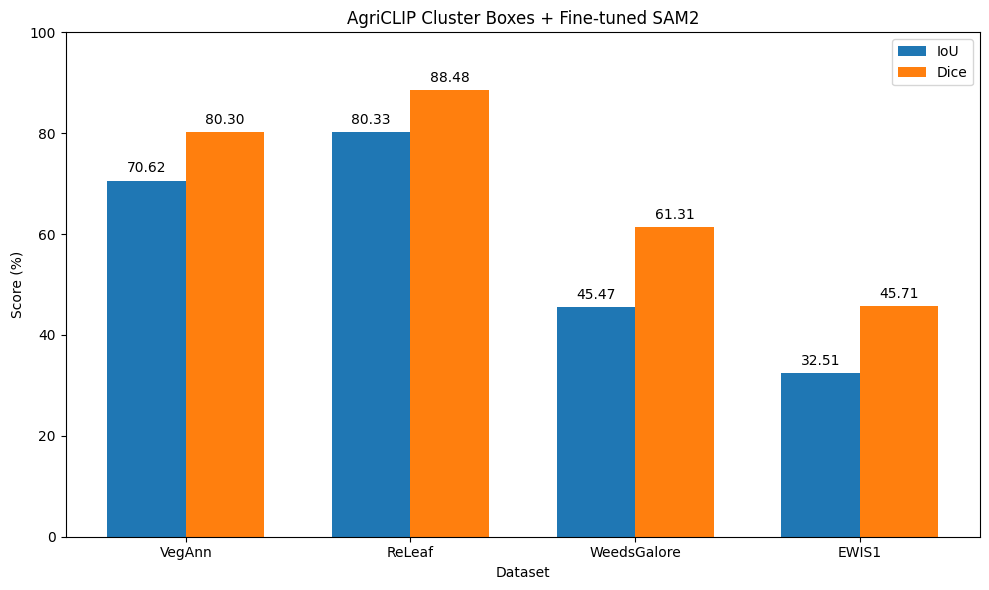

In [ ]:
x = np.arange(len(comparison))
width = 0.35

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width/2,
    comparison["IoU"],
    width,
    label="IoU"
)

bars2 = plt.bar(
    x + width/2,
    comparison["Dice"],
    width,
    label="Dice"
)

plt.ylabel("Score (%)")
plt.xlabel("Dataset")
plt.title("AgriCLIP Cluster Boxes + Fine-tuned SAM2")

plt.xticks(
    x,
    comparison["Dataset"]
)

plt.ylim(0, 100)

plt.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 1,
            f"{height:.2f}",
            ha="center",
            va="bottom"
        )

plt.tight_layout()
plt.show()

In [61]:
import numpy as np


def box_iou(box_a, box_b):
    

    box_a = np.asarray(box_a, dtype=np.float32)
    box_b = np.asarray(box_b, dtype=np.float32)

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    # Intersection
    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    intersection_width = max(0, ix2 - ix1)
    intersection_height = max(0, iy2 - iy1)

    intersection = (
        intersection_width *
        intersection_height
    )

    # Areas
    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0

    return intersection / union

In [62]:
#convert Seg mask to GT BB 
def mask_to_bbox(mask):
   

    mask = np.asarray(mask)

    # Remove unnecessary channel dimension
    if mask.ndim == 3:
        if mask.shape[-1] in [1, 3, 4]:
            mask = np.any(mask > 0, axis=-1)

    if mask.ndim != 2:
        raise ValueError(
            f"Expected 2D mask, got shape {mask.shape}"
        )

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return None

    return np.array(
        [
            xs.min(),
            ys.min(),
            xs.max(),
            ys.max()
        ],
        dtype=np.float32
    )

In [63]:
def merge_boxes(boxes):
    """
    Merge multiple cluster boxes into one enclosing box.

    boxes:
        numpy array of shape (N, 4)
        [x1, y1, x2, y2]
    """

    boxes = np.asarray(boxes, dtype=np.float32)

    if boxes.size == 0:
        return None

    if boxes.ndim != 2 or boxes.shape[1] != 4:
        raise ValueError(
            f"Expected boxes with shape (N, 4), got {boxes.shape}"
        )

    return np.array(
        [
            boxes[:, 0].min(),
            boxes[:, 1].min(),
            boxes[:, 2].max(),
            boxes[:, 3].max()
        ],
        dtype=np.float32
    )

In [73]:
# ============================================================
# INITIALIZE VEGANN
# ============================================================

from datasets import load_dataset

VEGANN_DATASET = "simonMadec/VegAnn"

vegann = load_dataset(
    VEGANN_DATASET
)

print("VegAnn loaded successfully.")
print("Available splits:", vegann.keys())

for split_name in vegann.keys():
    print(
        f"{split_name}: {len(vegann[split_name])} images"
    )

VegAnn loaded successfully.
Available splits: dict_keys(['train'])
train: 3775 images


In [75]:
#Create train/val split 

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print(
    "Training images:",
    len(train_hf)
)

print(
    "Validation images:",
    len(val_hf)
)

Training images: 3020
Validation images: 755


In [77]:
# ------------------------------------------------------------
# TEST BOX IoU ON ONE VEGANN IMAGE
# ------------------------------------------------------------

sample_index = 0

sample = val_hf[sample_index]

image = sample["image"]
gt_mask = sample["mask"]

# Make sure image is RGB
if not isinstance(image, Image.Image):
    image = Image.fromarray(
        np.asarray(image)
    )

image = image.convert("RGB")

# Make sure GT mask is 2D binary
gt_mask = np.asarray(gt_mask)

if gt_mask.ndim == 3:
    gt_mask = np.any(
        gt_mask > 0,
        axis=2
    )

gt_mask = (
    gt_mask > 0
).astype(np.uint8)


# ------------------------------------------------------------
# Generate clusters
# ------------------------------------------------------------

cluster_result = generate_agriclip_cluster_boxes(
    image,
    top_k=8,
    margin=25
)

print("Cluster result type:")
print(type(cluster_result))

print("\nCluster result keys:")
print(cluster_result.keys())

print("\nCluster boxes:")
print(cluster_result["boxes"])


# ------------------------------------------------------------
# GT bounding box
# ------------------------------------------------------------

gt_box = mask_to_bbox(
    gt_mask
)


# ------------------------------------------------------------
# Merge cluster boxes
# ------------------------------------------------------------

merged_box = merge_boxes(
    cluster_result["boxes"]
)


# ------------------------------------------------------------
# Calculate IoU
# ------------------------------------------------------------

iou = box_iou(
    gt_box,
    merged_box
)


print("\nGT box:")
print(gt_box)

print("\nMerged cluster box:")
print(merged_box)

print(
    f"\nCluster Box IoU: {iou * 100:.2f}%"
)

Cluster result type:
<class 'dict'>

Cluster result keys:
dict_keys(['boxes', 'cluster_scores', 'cluster_sizes', 'num_clusters', 'scores', 'topk_indices', 'grid_h', 'grid_w', 'selected_grid', 'labeled_grid'])

Cluster boxes:
[[ 48  48 463 317]]

GT box:
[  0.   0. 511. 511.]

Merged cluster box:
[ 48.  48. 463. 317.]

Cluster Box IoU: 42.75%


In [79]:
# ============================================================
# VEGANN — CLUSTER BOX IoU
# ============================================================

from tqdm.auto import tqdm
import numpy as np
from PIL import Image

vegann_box_results = []

for idx in tqdm(range(len(val_hf))):

    try:

        # ----------------------------------------------------
        # Load image and GT mask
        # ----------------------------------------------------

        sample = val_hf[idx]

        image = sample["image"]
        gt_mask = sample["mask"]

        # Make sure image is RGB
        if not isinstance(image, Image.Image):

            image = Image.fromarray(
                np.asarray(image)
            )

        image = image.convert("RGB")

        # Make sure GT mask is 2D binary
        gt_mask = np.asarray(gt_mask)

        if gt_mask.ndim == 3:

            gt_mask = np.any(
                gt_mask > 0,
                axis=2
            )

        gt_mask = (
            gt_mask > 0
        ).astype(np.uint8)


        # ----------------------------------------------------
        # Generate AgriCLIP cluster boxes
        # ----------------------------------------------------

        cluster_result = generate_agriclip_cluster_boxes(
            image,
            top_k=8,
            margin=25
        )

        cluster_boxes = cluster_result["boxes"]


        # ----------------------------------------------------
        # GT bounding box
        # ----------------------------------------------------

        gt_box = mask_to_bbox(
            gt_mask
        )

        if gt_box is None:
            continue


        # ----------------------------------------------------
        # Merge all cluster boxes
        # ----------------------------------------------------

        merged_box = merge_boxes(
            cluster_boxes
        )

        if merged_box is None:
            continue


        # ----------------------------------------------------
        # Calculate Box IoU
        # ----------------------------------------------------

        iou = box_iou(
            gt_box,
            merged_box
        )


        # ----------------------------------------------------
        # Store result
        # ----------------------------------------------------

        vegann_box_results.append({

            "image_id": idx,

            "box_iou": float(iou),

            "num_clusters":
                cluster_result["num_clusters"]

        })


    except Exception as e:

        print(
            f"Failed image {idx}: {e}"
        )


# ============================================================
# SUMMARY
# ============================================================

print("\n==============================================")
print("VegAnn Cluster Box Evaluation")
print("==============================================")

print(
    "Total images:",
    len(val_hf)
)

print(
    "Successful:",
    len(vegann_box_results)
)

print(
    "Failed:",
    len(val_hf) - len(vegann_box_results)
)


if len(vegann_box_results) > 0:

    mean_box_iou = np.mean([
        r["box_iou"]
        for r in vegann_box_results
    ])

    mean_clusters = np.mean([
        r["num_clusters"]
        for r in vegann_box_results
    ])

    print(
        f"Mean Cluster Box IoU: "
        f"{mean_box_iou * 100:.2f}%"
    )

    print(
        f"Mean Number of Clusters: "
        f"{mean_clusters:.2f}"
    )

  0%|          | 0/755 [00:00<?, ?it/s]


VegAnn Cluster Box Evaluation
Total images: 755
Successful: 746
Failed: 9
Mean Cluster Box IoU: 71.54%
Mean Number of Clusters: 3.15


In [81]:
def evaluate_box_iou(
    dataset_name,
    samples,
    get_image_fn,
    get_mask_fn,
    cluster_fn,
    max_samples=None
):

    results = []

    if max_samples is not None:
        samples = samples[:max_samples]

    print("=" * 60)
    print(dataset_name)
    print("=" * 60)

    for idx, sample in enumerate(
        tqdm(samples)
    ):

        try:

            # -------------------------
            # Image
            # -------------------------
            image = get_image_fn(sample)

            # -------------------------
            # GT mask
            # -------------------------
            gt_mask = get_mask_fn(
                sample,
                image
            )

            # -------------------------
            # GT bounding box
            # -------------------------
            gt_box = mask_to_bbox(
                gt_mask
            )

            if gt_box is None:
                continue

            # -------------------------
            # Cluster boxes
            # -------------------------
            cluster_result = cluster_fn(
                image
            )

            cluster_boxes = cluster_result["boxes"]

            if len(cluster_boxes) == 0:
                continue

            # -------------------------
            # Merge cluster boxes
            # -------------------------
            merged_box = merge_boxes(
                cluster_boxes
            )

            # -------------------------
            # Box IoU
            # -------------------------
            iou = box_iou(
                gt_box,
                merged_box
            )

            results.append({
                "index": idx,
                "box_iou": float(iou),
                "num_clusters": int(
                    cluster_result["num_clusters"]
                )
            })

        except Exception as e:

            print(
                f"Failed image {idx}: {e}"
            )

    if len(results) == 0:

        print("\nNo successful samples.")

        return results

    mean_iou = np.mean([
        r["box_iou"]
        for r in results
    ])

    mean_clusters = np.mean([
        r["num_clusters"]
        for r in results
    ])

    print("\nResults")
    print("-" * 40)

    print(
        f"Images: {len(results)}"
    )

    print(
        f"Mean Cluster Box IoU: "
        f"{mean_iou * 100:.2f}%"
    )

    print(
        f"Mean Number of Clusters: "
        f"{mean_clusters:.2f}"
    )

    return results

In [82]:
# ============================================================
# RELEAF — CLUSTER BOX IoU
# ============================================================

releaf_box_results = []

for idx, sample in enumerate(
    tqdm(releaf_samples)
):

    try:

        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------

        image = releaf_get_image(
            sample
        )

        # ----------------------------------------------------
        # Load GT segmentation mask
        # ----------------------------------------------------

        gt_mask = releaf_get_mask_for_eval(
            sample,
            image
        )

        gt_mask = np.asarray(
            gt_mask
        )

        # Make sure GT mask is 2D binary
        if gt_mask.ndim == 3:

            gt_mask = np.any(
                gt_mask > 0,
                axis=2
            )

        gt_mask = (
            gt_mask > 0
        ).astype(np.uint8)

        # ----------------------------------------------------
        # Generate AgriCLIP clusters
        # ----------------------------------------------------

        cluster_result = (
            generate_agriclip_cluster_boxes(
                image,
                top_k=8,
                margin=25
            )
        )

        cluster_boxes = (
            cluster_result["boxes"]
        )

        # ----------------------------------------------------
        # GT bounding box
        # ----------------------------------------------------

        gt_box = mask_to_bbox(
            gt_mask
        )

        if gt_box is None:
            continue

        # ----------------------------------------------------
        # Merge all cluster boxes
        # ----------------------------------------------------

        merged_box = merge_boxes(
            cluster_boxes
        )

        if merged_box is None:
            continue

        # ----------------------------------------------------
        # Box IoU
        # ----------------------------------------------------

        iou = box_iou(
            gt_box,
            merged_box
        )

        # ----------------------------------------------------
        # Store result
        # ----------------------------------------------------

        releaf_box_results.append({

            "image_id": idx,

            "num_clusters":
                cluster_result["num_clusters"],

            "cluster_box_iou":
                float(iou)

        })

    except Exception as e:

        print(
            f"Failed ReLeaf image {idx}: {e}"
        )


# ============================================================
# RESULTS
# ============================================================

releaf_box_df = pd.DataFrame(
    releaf_box_results
)

print(
    "\n================================"
)

print(
    "ReLeaf Cluster Box Evaluation"
)

print(
    "================================"
)

print(
    "Successful:",
    len(releaf_box_df)
)

if len(releaf_box_df) > 0:

    print(
        f"Mean Cluster Box IoU: "
        f"{releaf_box_df['cluster_box_iou'].mean() * 100:.2f}%"
    )

    print(
        f"Mean Number of Clusters: "
        f"{releaf_box_df['num_clusters'].mean():.2f}"
    )
    
    

  0%|          | 0/345 [00:00<?, ?it/s]


ReLeaf Cluster Box Evaluation
Successful: 345
Mean Cluster Box IoU: 84.46%
Mean Number of Clusters: 3.60


In [84]:
# ============================================================
# WEEDSGALORE — CLUSTER BOX IoU
# ============================================================

weedsgalore_box_results = []

for idx, sample in enumerate(tqdm(weedsgalore_pairs)):

    try:
        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------
        image = Image.open(sample["image"]).convert("RGB")

        # ----------------------------------------------------
        # Load GT segmentation mask
        # ----------------------------------------------------
        gt_mask = np.array(Image.open(sample["mask"]))

        # Make sure GT mask is 2D binary
        if gt_mask.ndim == 3:
            gt_mask = gt_mask[..., 0]

        gt_mask = (gt_mask > 0).astype(np.uint8)

        # ----------------------------------------------------
        # Generate AgriCLIP clusters
        # ----------------------------------------------------
        cluster_result = generate_agriclip_cluster_boxes(
            image, top_k=8, margin=25
        )

        cluster_boxes = cluster_result["boxes"]

        # ----------------------------------------------------
        # GT bounding box
        # ----------------------------------------------------
        gt_box = mask_to_bbox(gt_mask)

        if gt_box is None:
            continue

        # ----------------------------------------------------
        # Merge all cluster boxes
        # ----------------------------------------------------
        merged_box = merge_boxes(cluster_boxes)

        if merged_box is None:
            continue

        # ----------------------------------------------------
        # Box IoU
        # ----------------------------------------------------
        iou = box_iou(gt_box, merged_box)

        # ----------------------------------------------------
        # Store result
        # ----------------------------------------------------
        # Convert path to string or name safely
        image_name = (
            sample["image"].name
            if hasattr(sample["image"], "name")
            else str(sample["image"])
        )

        weedsgalore_box_results.append(
            {
                "image_id": idx,
                "image_name": image_name,
                "num_clusters": cluster_result["num_clusters"],
                "cluster_box_iou": float(iou),
            }
        )

    except Exception as e:
        print(f"Failed WeedsGalore image {idx}: {e}")


# ============================================================
# RESULTS
# ============================================================

weedsgalore_box_df = pd.DataFrame(weedsgalore_box_results)

print("\n================================")
print("WeedsGalore Cluster Box Evaluation")
print("================================")
print("Successful:", len(weedsgalore_box_df))

if len(weedsgalore_box_df) > 0:
    print(
        f"Mean Cluster Box IoU: "
        f"{weedsgalore_box_df['cluster_box_iou'].mean() * 100:.2f}%"
    )

    print(
        f"Mean Number of Clusters: "
        f"{weedsgalore_box_df['num_clusters'].mean():.2f}"
    )


  0%|          | 0/156 [00:00<?, ?it/s]


WeedsGalore Cluster Box Evaluation
Successful: 156
Mean Cluster Box IoU: 76.59%
Mean Number of Clusters: 3.25


In [86]:
# ============================================================
# EWIS1 — CLUSTER BOX IoU
# ============================================================

ewis1_box_results = []

for idx, sample in enumerate(tqdm(ewis1_pairs)):

    try:
        # ----------------------------------------------------
        # Load image
        # ----------------------------------------------------
        image = Image.open(sample["image"]).convert("RGB")

        # ----------------------------------------------------
        # Load GT segmentation mask
        # ----------------------------------------------------
        gt_mask = np.array(Image.open(sample["mask"]))

        # Make sure GT mask is 2D binary
        if gt_mask.ndim == 3:
            gt_mask = gt_mask[..., 0]

        gt_mask = (gt_mask > 0).astype(np.uint8)

        # ----------------------------------------------------
        # Generate AgriCLIP clusters
        # ----------------------------------------------------
        cluster_result = generate_agriclip_cluster_boxes(
            image, top_k=8, margin=25
        )

        cluster_boxes = cluster_result["boxes"]

        # ----------------------------------------------------
        # GT bounding box
        # ----------------------------------------------------
        gt_box = mask_to_bbox(gt_mask)

        if gt_box is None:
            continue

        # ----------------------------------------------------
        # Merge all cluster boxes
        # ----------------------------------------------------
        merged_box = merge_boxes(cluster_boxes)

        if merged_box is None:
            continue

        # ----------------------------------------------------
        # Box IoU
        # ----------------------------------------------------
        iou = box_iou(gt_box, merged_box)

        # ----------------------------------------------------
        # Store result
        # ----------------------------------------------------
        # Safe image name extraction for both string paths and Path objects
        image_name = (
            sample["image"].name
            if hasattr(sample["image"], "name")
            else str(sample["image"])
        )

        ewis1_box_results.append(
            {
                "image_id": idx,
                "image_name": image_name,
                "num_clusters": cluster_result["num_clusters"],
                "cluster_box_iou": float(iou),
            }
        )

    except Exception as e:
        print(f"Failed EWIS1 image {idx}: {e}")


# ============================================================
# RESULTS
# ============================================================

ewis1_box_df = pd.DataFrame(ewis1_box_results)

print("\n================================")
print("EWIS1 Cluster Box Evaluation")
print("================================")
print("Successful:", len(ewis1_box_df))

if len(ewis1_box_df) > 0:
    print(
        f"Mean Cluster Box IoU: "
        f"{ewis1_box_df['cluster_box_iou'].mean() * 100:.2f}%"
    )

    print(
        f"Mean Number of Clusters: "
        f"{ewis1_box_df['num_clusters'].mean():.2f}"
    )


  0%|          | 0/88 [00:00<?, ?it/s]


EWIS1 Cluster Box Evaluation
Successful: 88
Mean Cluster Box IoU: 76.73%
Mean Number of Clusters: 3.28


             Final Agricultural Cross-Benchmark           
    Dataset  Seg_IoU  Dice  Box_IoU  Mean_Clusters
     VegAnn    70.62 80.30    71.54           3.15
     ReLeaf    80.33 88.48    84.46           3.60
WeedsGalore    45.47 61.31    76.59           3.25
      EWIS1    32.51 45.71    76.73           3.28



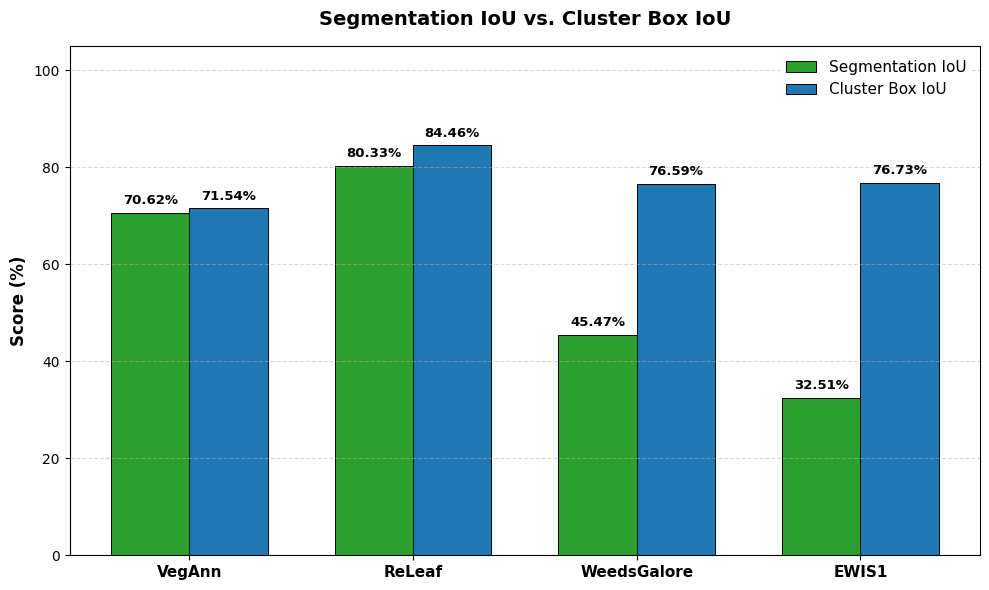

In [89]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Define the complete dataset from your evaluation logs
comparison = pd.DataFrame(
    {
        "Dataset": ["VegAnn", "ReLeaf", "WeedsGalore", "EWIS1"],
        "Seg_IoU": [70.62, 80.33, 45.47, 32.51],
        "Dice": [80.30, 88.48, 61.31, 45.71],
        "Box_IoU": [71.54, 84.46, 76.59, 76.73],
        "Mean_Clusters": [3.15, 3.60, 3.25, 3.28],
    }
)

# Display the clean DataFrame
print("==========================================================")
print("             Final Agricultural Cross-Benchmark           ")
print("==========================================================")
print(comparison.to_string(index=False))
print("==========================================================\n")

# 2. Setup plotting dimensions
x = np.arange(len(comparison["Dataset"]))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

# 3. Generate grouped bars
rects1 = ax.bar(
    x - width / 2,
    comparison["Seg_IoU"],
    width,
    label="Segmentation IoU",
    color="#2ca02c",
    edgecolor="black",
    linewidth=0.7,
)
rects2 = ax.bar(
    x + width / 2,
    comparison["Box_IoU"],
    width,
    label="Cluster Box IoU",
    color="#1f77b4",
    edgecolor="black",
    linewidth=0.7,
)

# 4. Annotate and style chart
ax.set_ylabel("Score (%)", fontsize=12, fontweight="bold")
ax.set_title(
    "Segmentation IoU vs. Cluster Box IoU",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xticks(x)
ax.set_xticklabels(comparison["Dataset"], fontsize=11, fontweight="bold")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(frameon=True, facecolor="white", edgecolor="none", fontsize=11)


# Function to automatically attach percentage labels on top of the bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f"{height:.2f}%",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 4),  # 4 points vertical offset
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold",
        )


autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()


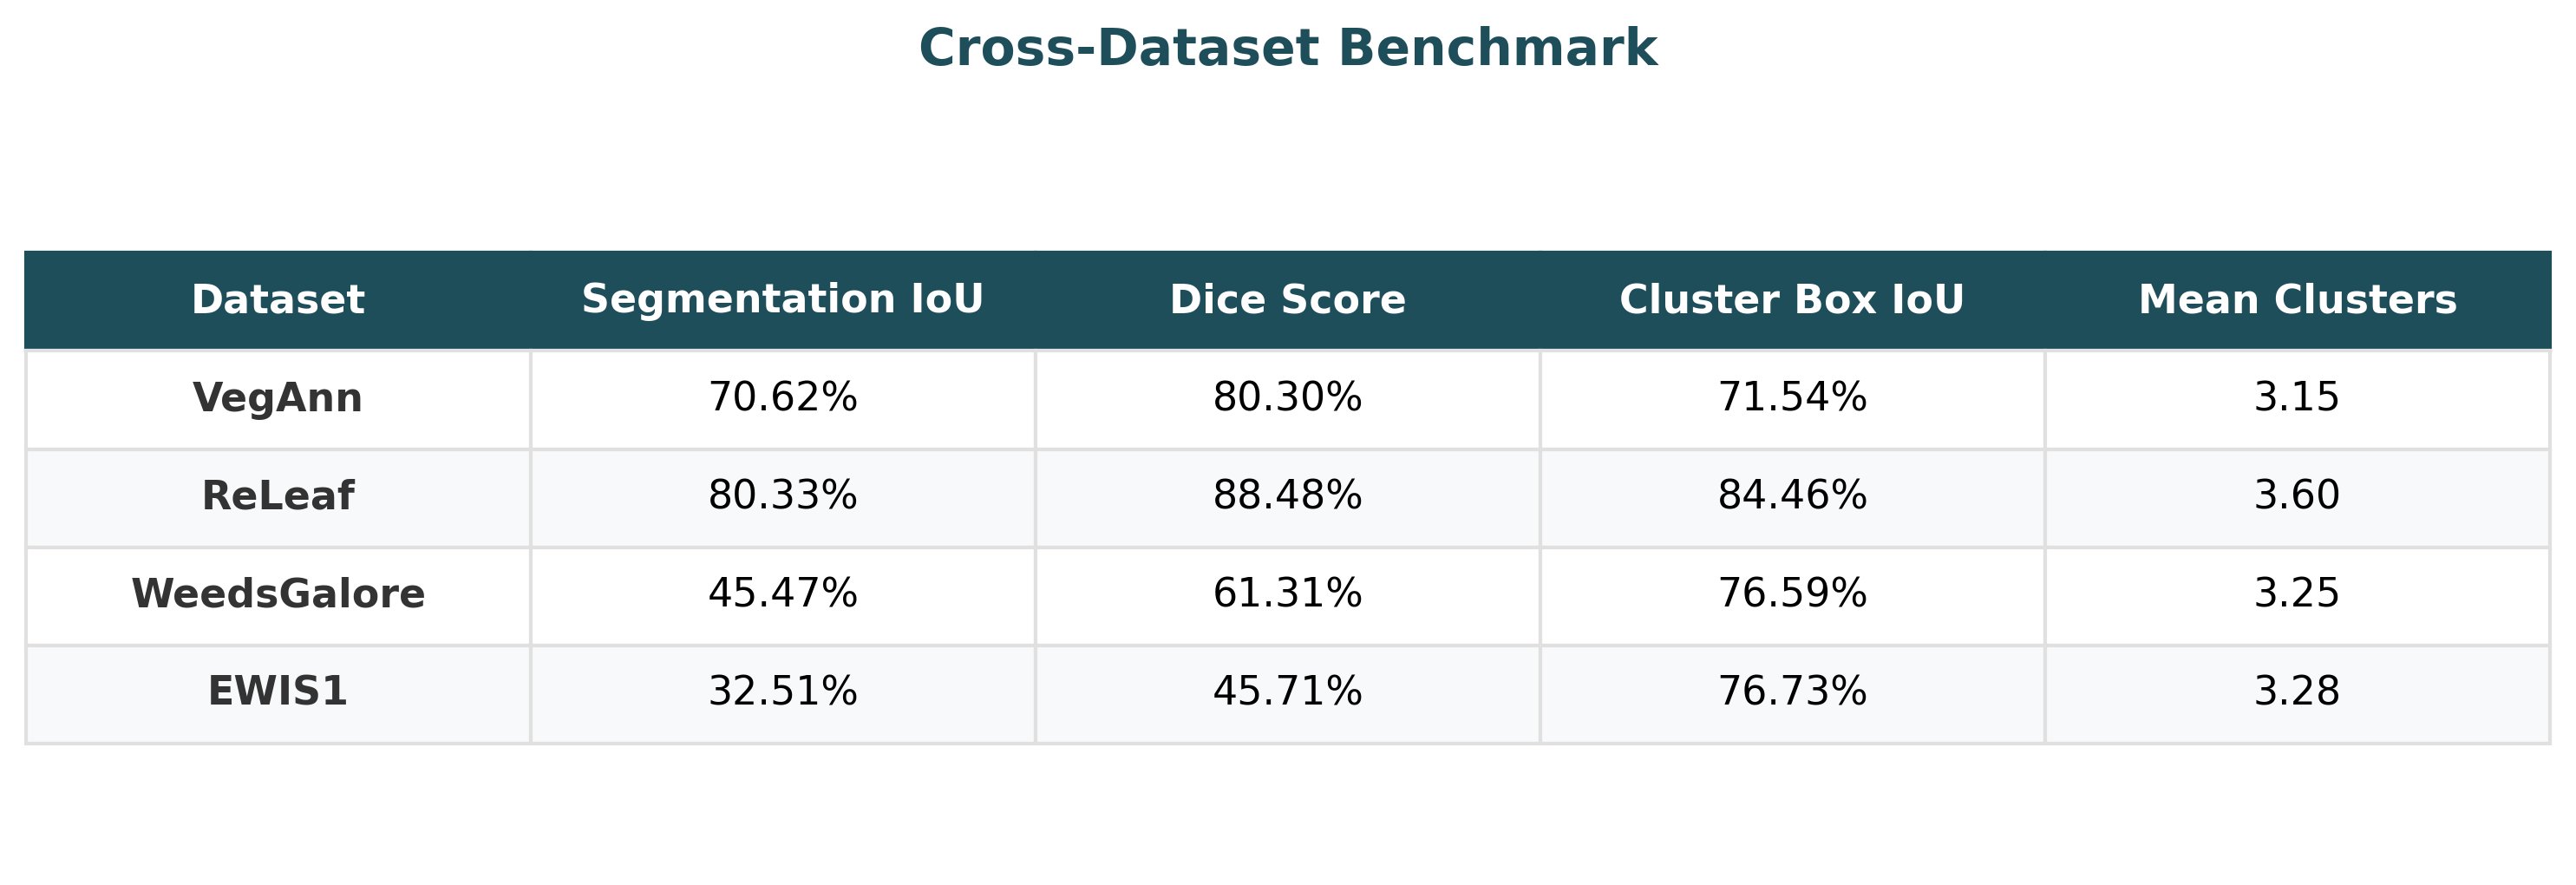

In [92]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Define the complete evaluation data
comparison = pd.DataFrame(
    {
        "Dataset": ["VegAnn", "ReLeaf", "WeedsGalore", "EWIS1"],
        "Segmentation IoU": ["70.62%", "80.33%", "45.47%", "32.51%"],
        "Dice Score": ["80.30%", "88.48%", "61.31%", "45.71%"],
        "Cluster Box IoU": ["71.54%", "84.46%", "76.59%", "76.73%"],
        "Mean Clusters": ["3.15", "3.60", "3.25", "3.28"],
    }
)

# 2. Initialize figure for a clean publication-ready table graphic
fig, ax = plt.subplots(figsize=(10, 3.5), dpi=300)
ax.axis("off")

# 3. Create the Matplotlib table
table = ax.table(
    cellText=comparison.values,
    colLabels=comparison.columns,
    cellLoc="center",
    loc="center",
)

# 4. Apply clean corporate styling (No bright neon colors)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.0, 2.2)  # Generous cell padding

# Style individual cells
for (row, col), cell in table.get_celld().items():
    # Header styling
    if row == 0:
        cell.set_text_props(weight="bold", color="white")
        cell.set_facecolor("#1f4e5b")  # Deep slate teal
        cell.set_edgecolor("#1f4e5b")
    # Body rows styling
    else:
        cell.set_edgecolor("#e0e0e0")
        # Alternating row colors for high readability
        if row % 2 == 0:
            cell.set_facecolor("#f8f9fa")
        else:
            cell.set_facecolor("#ffffff")

        # Bold dataset names
        if col == 0:
            cell.set_text_props(weight="bold", color="#333333")

# Title styling
plt.title(
    "Cross-Dataset Benchmark",
    fontsize=14,
    fontweight="bold",
    pad=20,
    color="#1f4e5b",
)

plt.tight_layout()
plt.savefig("publication_benchmark_table.png", bbox_inches="tight")
plt.show()


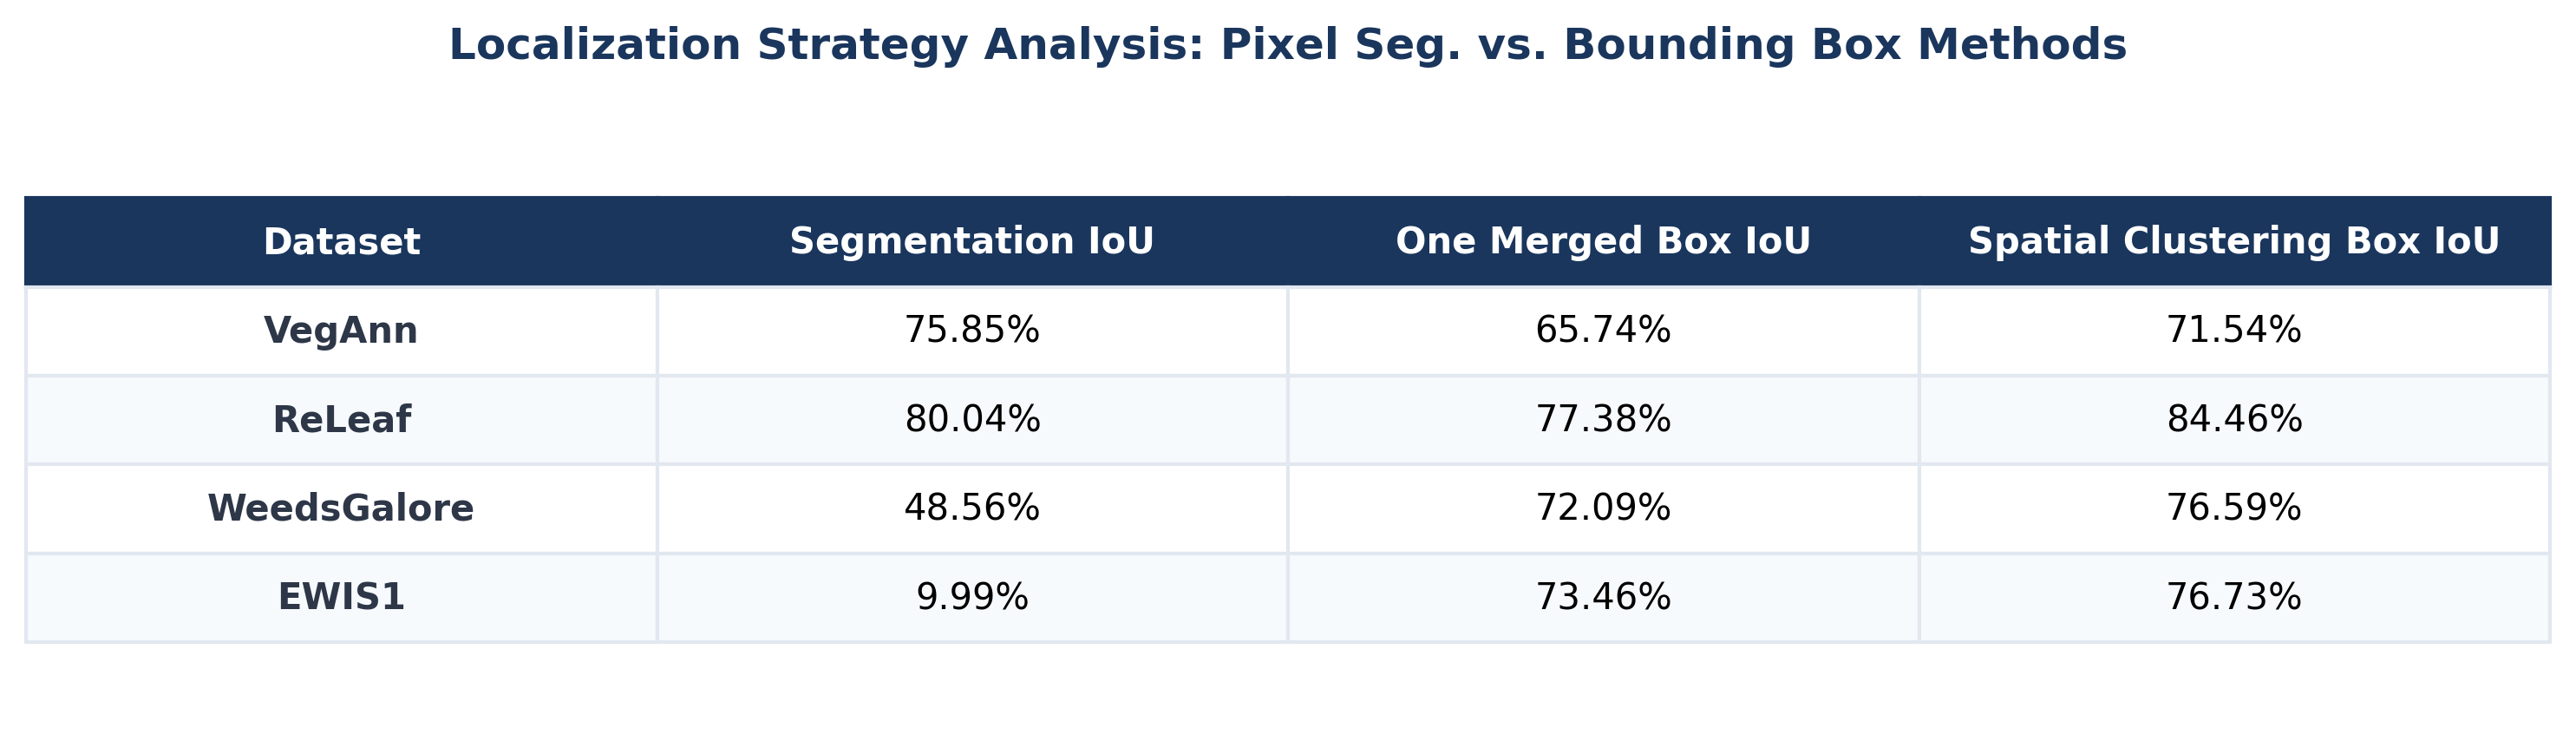

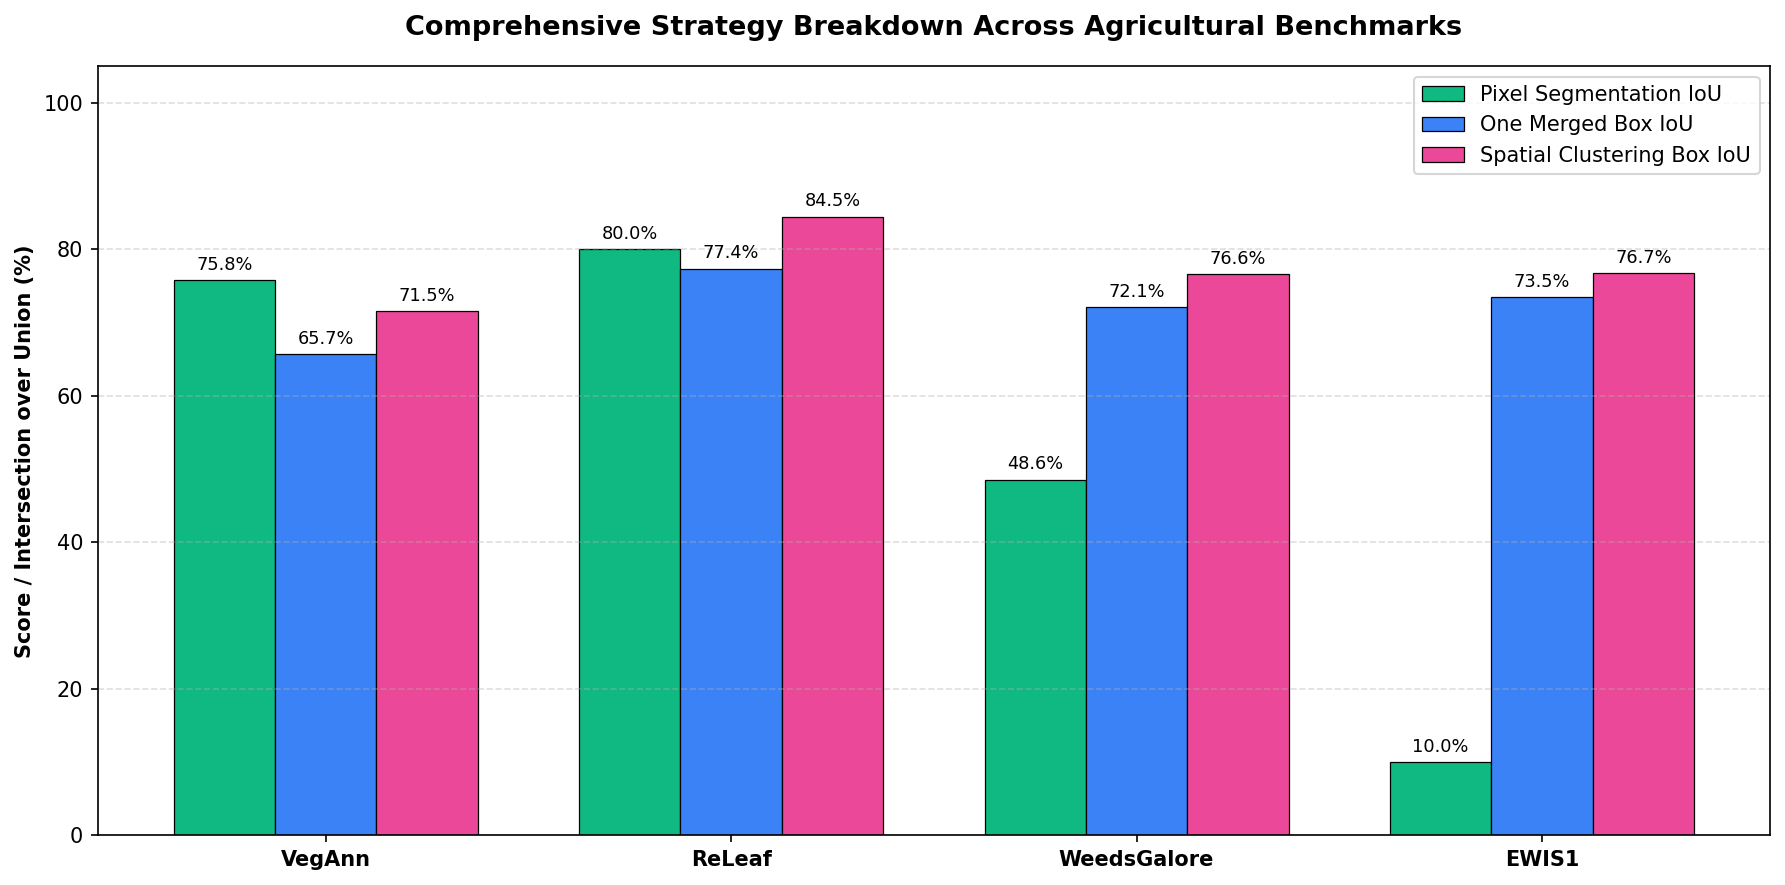

In [93]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Define the complete evaluation data combining all experiments
comparison_data = pd.DataFrame(
    {
        "Dataset": ["VegAnn", "ReLeaf", "WeedsGalore", "EWIS1"],
        "Segmentation IoU": [75.85, 80.04, 48.56, 9.99],
        "One Merged Box IoU": [65.74, 77.38, 72.09, 73.46],
        "Spatial Clustering Box IoU": [71.54, 84.46, 76.59, 76.73],
    }
)

# ----------------------------------------------------
# VISUAL 1: Publication-Ready Matplotlib Table
# ----------------------------------------------------
fig_tab, ax_tab = plt.subplots(figsize=(10, 3), dpi=300)
ax_tab.axis("off")

# Convert values to strings with percentage signs for formatting
display_df = comparison_data.copy()
for col in display_df.columns[1:]:
    display_df[col] = display_df[col].apply(lambda v: f"{v:.2f}%")

table = ax_tab.table(
    cellText=display_df.values,
    colLabels=display_df.columns,
    cellLoc="center",
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.0, 2.0)  # Row height padding

# Apply professional styling
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold", color="white")
        cell.set_facecolor("#1a365d")  # Deep Navy Blue Header
        cell.set_edgecolor("#1a365d")
    else:
        cell.set_edgecolor("#e2e8f0")
        if row % 2 == 0:
            cell.set_facecolor("#f7fafc")
        else:
            cell.set_facecolor("#ffffff")
        if col == 0:
            cell.set_text_props(weight="bold", color="#2d3748")

plt.title(
    "Localization Strategy Analysis: Pixel Seg. vs. Bounding Box Methods",
    fontsize=12,
    fontweight="bold",
    pad=15,
    color="#1a365d",
)
plt.tight_layout()
plt.savefig("localization_strategy_table.png", bbox_inches="tight")


# ----------------------------------------------------
# VISUAL 2: Side-by-Side Comparison Plot
# ----------------------------------------------------
x = np.arange(len(comparison_data["Dataset"]))
width = 0.25  # Thinner width to fit three bars side by side

fig_plot, ax_plot = plt.subplots(figsize=(12, 6), dpi=150)

# Generate 3 grouped bars per dataset
rects1 = ax_plot.bar(
    x - width,
    comparison_data["Segmentation IoU"],
    width,
    label="Pixel Segmentation IoU",
    color="#10b981",
    edgecolor="black",
    linewidth=0.6,
)
rects2 = ax_plot.bar(
    x,
    comparison_data["One Merged Box IoU"],
    width,
    label="One Merged Box IoU",
    color="#3b82f6",
    edgecolor="black",
    linewidth=0.6,
)
rects3 = ax_plot.bar(
    x + width,
    comparison_data["Spatial Clustering Box IoU"],
    width,
    label="Spatial Clustering Box IoU",
    color="#ec4899",
    edgecolor="black",
    linewidth=0.6,
)

# Annotations and formatting
ax_plot.set_ylabel("Score / Intersection over Union (%)", fontweight="bold")
ax_plot.set_title(
    "Comprehensive Strategy Breakdown Across Agricultural Benchmarks",
    fontweight="bold",
    fontsize=13,
    pad=15,
)
ax_plot.set_xticks(x)
ax_plot.set_xticklabels(comparison_data["Dataset"], fontweight="bold")
ax_plot.set_ylim(0, 105)
ax_plot.grid(axis="y", linestyle="--", alpha=0.4)
ax_plot.legend(loc="upper right", frameon=True, facecolor="white")


def add_labels(rects):
    for rect in rects:
        height = rect.get_height()
        ax_plot.annotate(
            f"{height:.1f}%",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.5,
        )


add_labels(rects1)
add_labels(rects2)
add_labels(rects3)

plt.tight_layout()
plt.savefig("localization_strategy_chart.png", bbox_inches="tight")
plt.show()


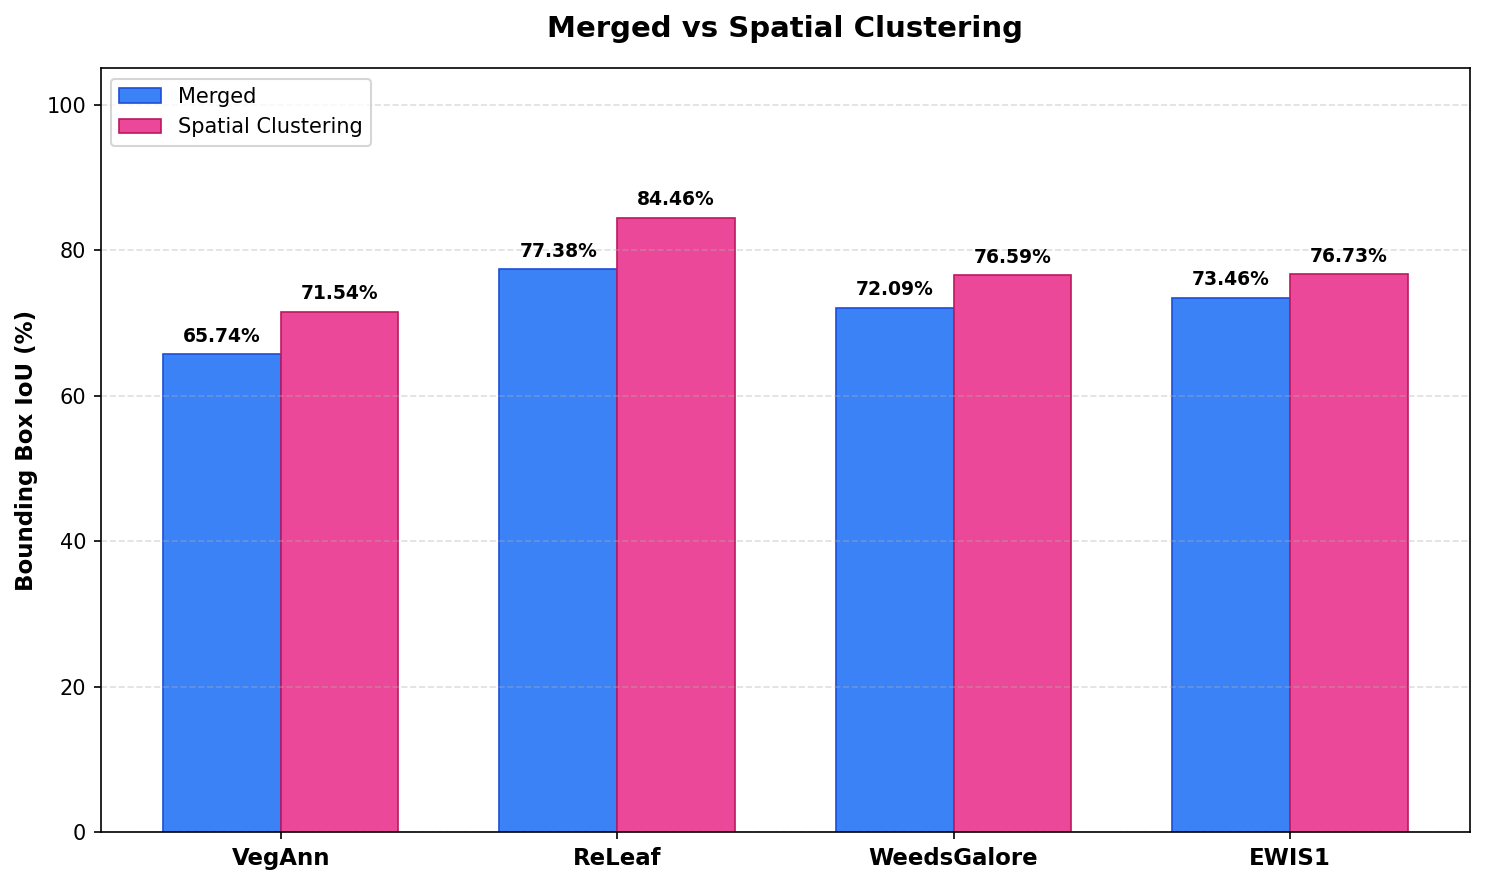

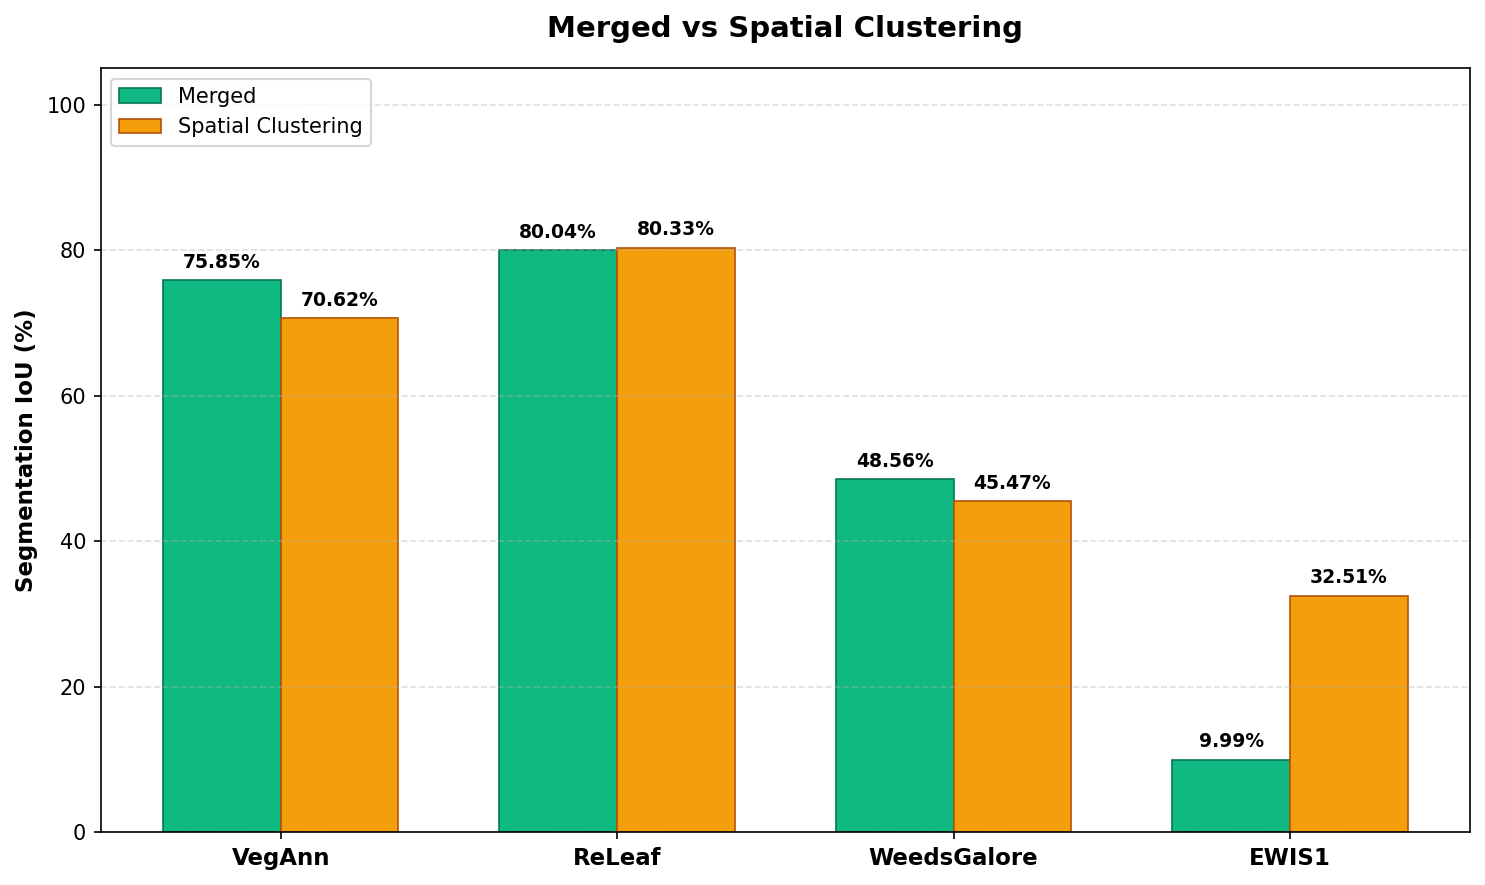

In [96]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Define the updated complete dataset
comparison_data = pd.DataFrame(
    {
        "Dataset": ["VegAnn", "ReLeaf", "WeedsGalore", "EWIS1"],
        # Box IoU Metrics
        "Merged_Box_IoU": [65.74, 77.38, 72.09, 73.46],
        "Spatial_Box_IoU": [71.54, 84.46, 76.59, 76.73],
        # Segmentation IoU Metrics
        "Merged_Seg_IoU": [75.85, 80.04, 48.56, 9.99],
        "Spatial_Seg_IoU": [70.62, 80.33, 45.47, 32.51],
    }
)


# Helper function to attach value labels on top of the bars
def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f"{height:.2f}%",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 4),  # 4 points vertical offset
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )


# Global setup for x-axis indexing
x = np.arange(len(comparison_data["Dataset"]))
width = 0.35

# ============================================================
# PLOT 1: BOX IOU COMPARISON
# ============================================================
fig1, ax1 = plt.subplots(figsize=(10, 6), dpi=150)

rects1_box = ax1.bar(
    x - width / 2,
    comparison_data["Merged_Box_IoU"],
    width,
    label="Merged",
    color="#3b82f6",
    edgecolor="#1d4ed8",
    linewidth=0.8,
)
rects2_box = ax1.bar(
    x + width / 2,
    comparison_data["Spatial_Box_IoU"],
    width,
    label="Spatial Clustering",
    color="#ec4899",
    edgecolor="#be185d",
    linewidth=0.8,
)

# Formatting
ax1.set_ylabel("Bounding Box IoU (%)", fontsize=11, fontweight="bold")
ax1.set_title("Merged vs Spatial Clustering", fontsize=14, fontweight="bold", pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(comparison_data["Dataset"], fontsize=11, fontweight="bold")
ax1.set_ylim(0, 105)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.legend(loc="upper left", frameon=True, facecolor="white")

autolabel(rects1_box, ax1)
autolabel(rects2_box, ax1)

plt.tight_layout()
plt.savefig("box_iou_comparison.png", bbox_inches="tight")
plt.show()


# ============================================================
# PLOT 2: SEGMENTATION IOU COMPARISON
# ============================================================
fig2, ax2 = plt.subplots(figsize=(10, 6), dpi=150)

rects1_seg = ax2.bar(
    x - width / 2,
    comparison_data["Merged_Seg_IoU"],
    width,
    label="Merged",
    color="#10b981",
    edgecolor="#047857",
    linewidth=0.8,
)
rects2_seg = ax2.bar(
    x + width / 2,
    comparison_data["Spatial_Seg_IoU"],
    width,
    label="Spatial Clustering",
    color="#f59e0b",
    edgecolor="#b45309",
    linewidth=0.8,
)

# Formatting
ax2.set_ylabel("Segmentation IoU (%)", fontsize=11, fontweight="bold")
ax2.set_title("Merged vs Spatial Clustering", fontsize=14, fontweight="bold", pad=15)
ax2.set_xticks(x)
ax2.set_xticklabels(comparison_data["Dataset"], fontsize=11, fontweight="bold")
ax2.set_ylim(0, 105)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.legend(loc="upper left", frameon=True, facecolor="white")

autolabel(rects1_seg, ax2)
autolabel(rects2_seg, ax2)

plt.tight_layout()
plt.savefig("segmentation_iou_comparison.png", bbox_inches="tight")
plt.show()


In [97]:
import time
import torch


def profile_pipeline_step(sample, image):
    # Track GPU Memory before step
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
        start_mem = torch.cuda.memory_allocated()

    start_time = time.time()

    # 1. RUN YOUR FEATURE EXTRACTION & ALIGNER
    # (Insert your DINO/ResNet code block here)

    # 2. RUN SPATIAL CLUSTERING
    # (Insert your clustering code block here)

    elapsed_time = time.time() - start_time

    if torch.cuda.is_available():
        peak_mem = torch.cuda.max_memory_allocated() - start_mem
    else:
        peak_mem = 0

    return {"latency_seconds": elapsed_time, "peak_vram_mb": peak_mem / (1024**2)}
